In [1]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------------- -------------------------- 3.1/9.5 MB 17.2 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 28.2 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 31.5 MB/s  0:00:00

   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- ----------------------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


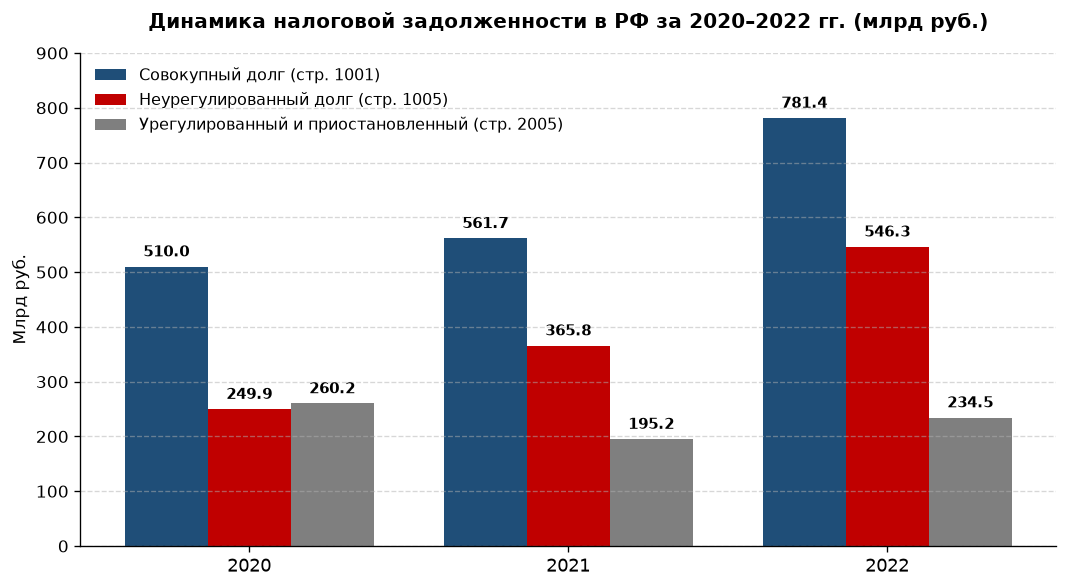

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.join("data_processed", "fns_debt_rf_2020_2022.csv"))
df["Код_строки"] = df["Код_строки"].astype(str).str.strip()
df["Млрд_руб"] = df["Всего_тыс_руб"] / 1_000_000

codes = ("1001", "1005", "2005")
sub = df[df["Код_строки"].isin(codes)].pivot(index="Год", columns="Код_строки", values="Млрд_руб")

years = sub.index.astype(str)
x = range(len(years))
width = 0.26

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

b1 = ax.bar([i - width for i in x], sub.get("1001"), width, label="Совокупный долг (стр. 1001)", color="#1f4e78")
b2 = ax.bar(x, sub.get("1005"), width, label="Неурегулированный долг (стр. 1005)", color="#c00000")
b3 = ax.bar([i + width for i in x], sub.get("2005"), width, label="Урегулированный и приостановленный (стр. 2005)", color="#7f7f7f")

for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}",
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_title("Динамика налоговой задолженности в РФ за 2020–2022 гг. (млрд руб.)", fontsize=12, fontweight="bold", pad=15)
ax.set_xticks(list(x))
ax.set_xticklabels(years, fontsize=11)
ax.set_ylabel("Млрд руб.", fontsize=10)
ax.set_ylim(0, 900)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="upper left", fontsize=9.5)

plt.tight_layout()
plt.show()


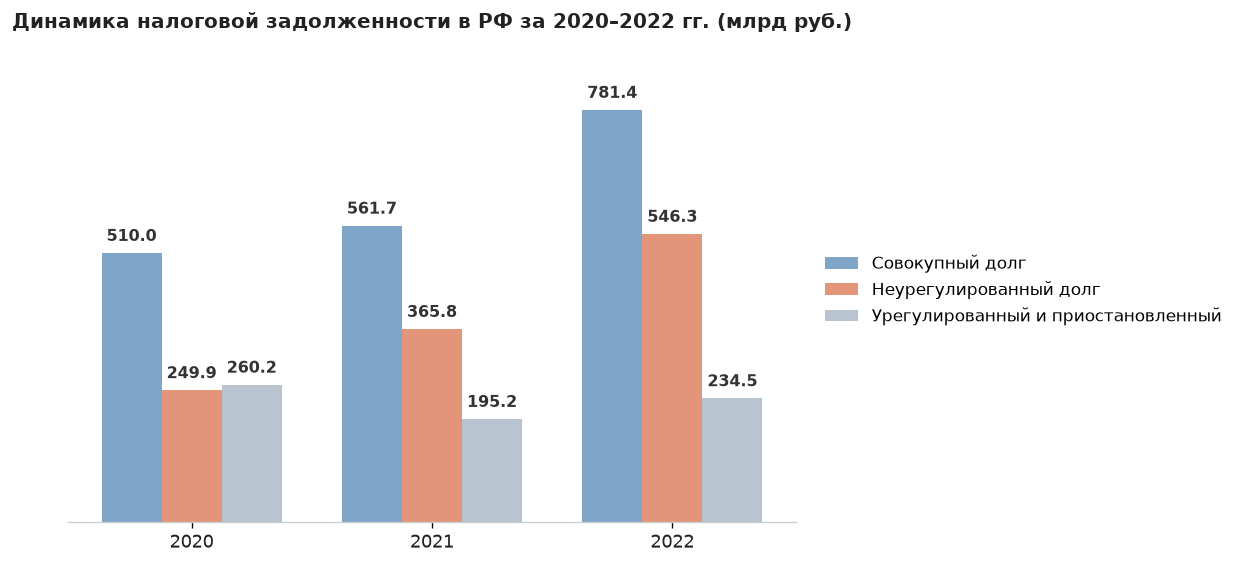

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.join("data_processed", "fns_debt_rf_2020_2022.csv"))
df["Код_строки"] = df["Код_строки"].astype(str).str.strip()
df["Млрд_руб"] = df["Всего_тыс_руб"] / 1_000_000

codes = ("1001", "1005", "2005")
sub = df[df["Код_строки"].isin(codes)].pivot(index="Год", columns="Код_строки", values="Млрд_руб")

years = sub.index.astype(str)
x = range(len(years))
width = 0.25

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, ax = plt.subplots(figsize=(10, 4.8), dpi=120)

# Спокойная деловая пастельная палитра
b1 = ax.bar([i - width for i in x], sub.get("1001"), width, label="Совокупный долг", color="#7FA6C9")
b2 = ax.bar(x, sub.get("1005"), width, label="Неурегулированный долг", color="#E29578")
b3 = ax.bar([i + width for i in x], sub.get("2005"), width, label="Урегулированный и приостановленный", color="#B8C4D0")

# Подписи значений над столбцами
for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}",
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 5), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#333333")

ax.set_title("Динамика налоговой задолженности в РФ за 2020–2022 гг. (млрд руб.)", fontsize=12, fontweight="bold", pad=18, color="#222222")
ax.set_xticks(list(x))
ax.set_xticklabels(years, fontsize=11, color="#222222")
ax.set_ylim(0, 880)

# Убираем ось Y, шкалу слева и все лишние рамки, оставляя только базовую линию снизу
ax.yaxis.set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#CCCCCC")

# Выносим легенду вправо за пределы графика
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=10)

plt.tight_layout()
plt.show()


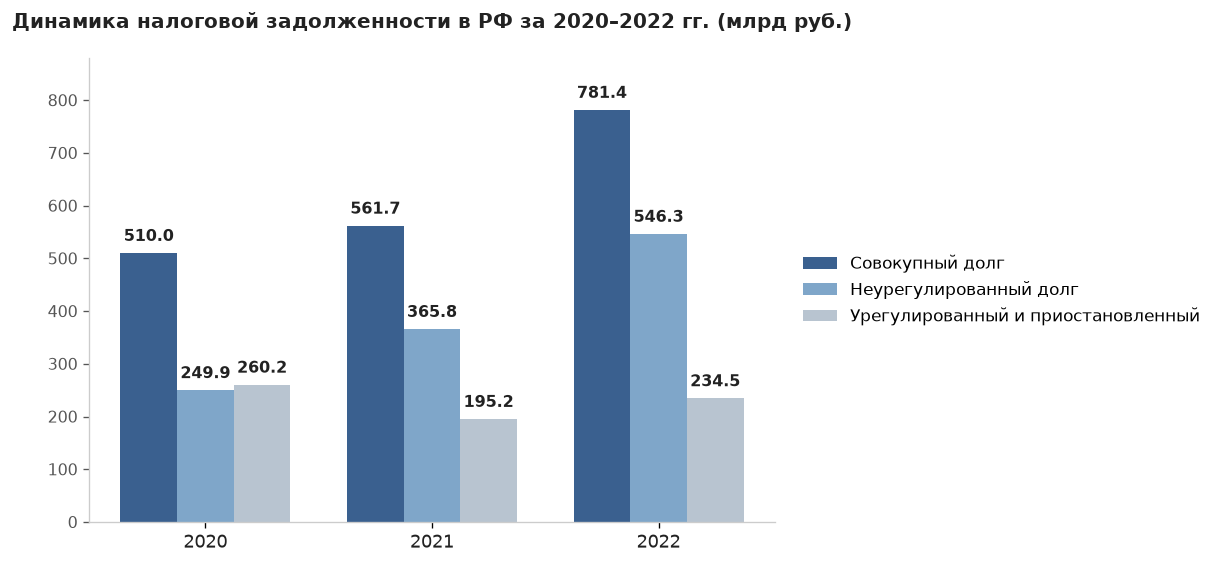

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.join("data_processed", "fns_debt_rf_2020_2022.csv"))
df["Код_строки"] = df["Код_строки"].astype(str).str.strip()
df["Млрд_руб"] = df["Всего_тыс_руб"] / 1_000_000

codes = ("1001", "1005", "2005")
sub = df[df["Код_строки"].isin(codes)].pivot(index="Год", columns="Код_строки", values="Млрд_руб")

years = sub.index.astype(str)
x = range(len(years))
width = 0.25

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, ax = plt.subplots(figsize=(10, 4.8), dpi=120)

# Единая деловая палитра (оттенки синего и серо-стального по стандартам финансовой отчетности)
b1 = ax.bar([i - width for i in x], sub.get("1001"), width, label="Совокупный долг", color="#3A608F")
b2 = ax.bar(x, sub.get("1005"), width, label="Неурегулированный долг", color="#7FA6C9")
b3 = ax.bar([i + width for i in x], sub.get("2005"), width, label="Урегулированный и приостановленный", color="#B8C4D0")

for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}",
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 5), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#222222")

ax.set_title("Динамика налоговой задолженности в РФ за 2020–2022 гг. (млрд руб.)", fontsize=12, fontweight="bold", pad=18, color="#222222")
ax.set_xticks(list(x))
ax.set_xticklabels(years, fontsize=11, color="#222222")
ax.set_ylim(0, 880)

# Оставляем ось Y с цифрами без подписи единиц измерения и убираем верхнюю и правую рамки
ax.tick_params(axis="y", labelsize=9.5, colors="#555555")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=10)

plt.tight_layout()
plt.show()


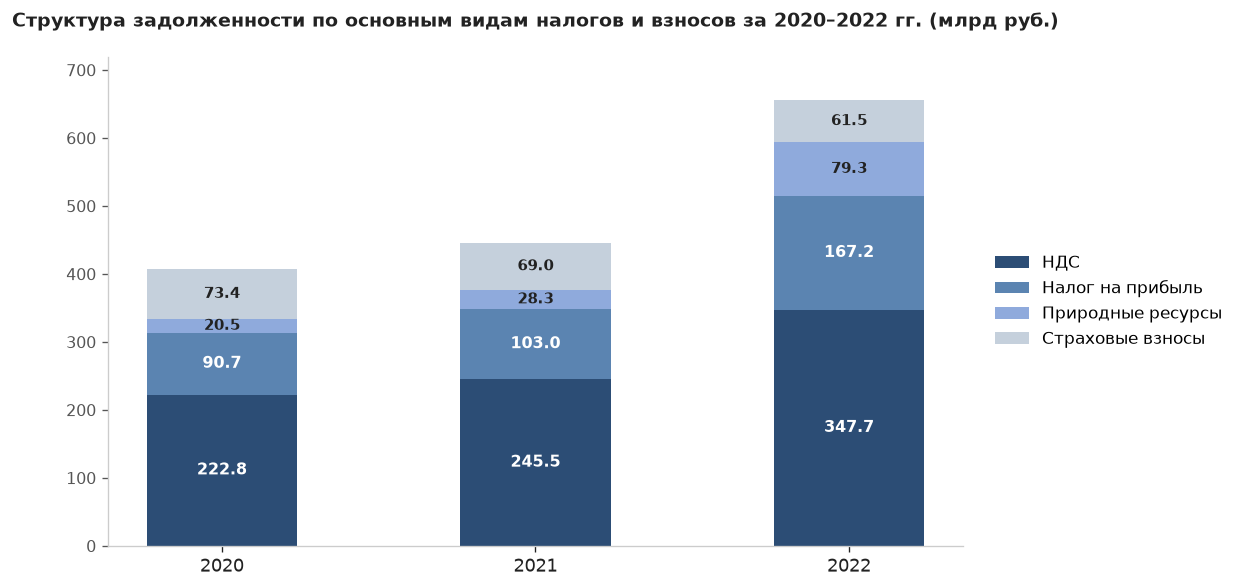

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.join("data_processed", "fns_debt_rf_2020_2022.csv"))
df["Код_строки"] = df["Код_строки"].astype(str).str.strip()

# Берем строку 1001 (Совокупная задолженность) и переводим в млрд руб.
sub_tax = df[df["Код_строки"] == "1001"].sort_values("Год").copy()
years = sub_tax["Год"].astype(str)

vat = sub_tax["НДС_тыс_руб"] / 1_000_000
profit = sub_tax["Налог_на_прибыль_тыс_руб"] / 1_000_000
resources = sub_tax["Природные_ресурсы_тыс_руб"] / 1_000_000
insurance = sub_tax["Страховые_взносы_тыс_руб"] / 1_000_000

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, ax = plt.subplots(figsize=(10, 5), dpi=120)

width = 0.48
p1 = ax.bar(years, vat, width, label="НДС", color="#2C4D75")
p2 = ax.bar(years, profit, width, bottom=vat, label="Налог на прибыль", color="#5B84B1")
p3 = ax.bar(years, resources, width, bottom=vat + profit, label="Природные ресурсы", color="#8FAADC")
p4 = ax.bar(years, insurance, width, bottom=vat + profit + resources, label="Страховые взносы", color="#C5D0DC")

# Подписи значений внутри каждого сегмента столбца
for i in range(len(years)):
    v_val = vat.iloc[i]
    p_val = profit.iloc[i]
    r_val = resources.iloc[i]
    ins_val = insurance.iloc[i]
    
    ax.text(i, v_val / 2, f"{v_val:.1f}", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    ax.text(i, v_val + p_val / 2, f"{p_val:.1f}", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    ax.text(i, v_val + p_val + r_val / 2, f"{r_val:.1f}", ha="center", va="center", color="#222222", fontweight="bold", fontsize=9)
    ax.text(i, v_val + p_val + r_val + ins_val / 2, f"{ins_val:.1f}", ha="center", va="center", color="#222222", fontweight="bold", fontsize=9)

ax.set_title("Структура задолженности по основным видам налогов и взносов за 2020–2022 гг. (млрд руб.)", fontsize=11.5, fontweight="bold", pad=18, color="#222222")
ax.set_ylim(0, 720)

# Единые правила оформления осей, рамок и легенды
ax.tick_params(axis="x", labelsize=11, colors="#222222")
ax.tick_params(axis="y", labelsize=9.5, colors="#555555")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=10)

plt.tight_layout()
plt.show()


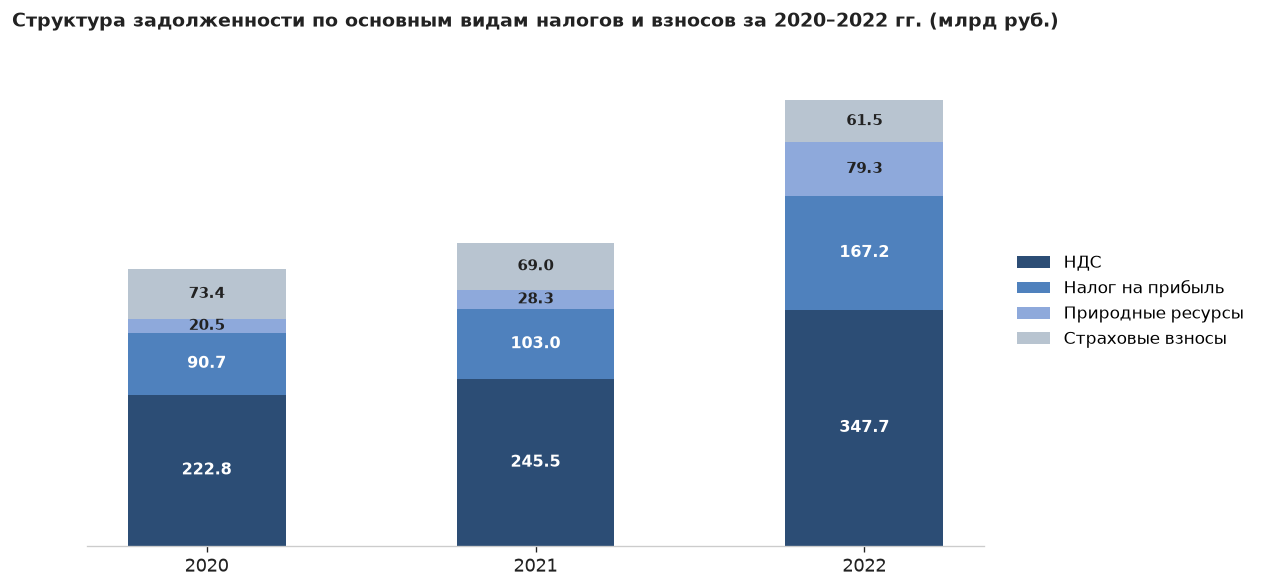

In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.join("data_processed", "fns_debt_rf_2020_2022.csv"))
df["Код_строки"] = df["Код_строки"].astype(str).str.strip()

sub_tax = df[df["Код_строки"] == "1001"].sort_values("Год").copy()
years = sub_tax["Год"].astype(str)

vat = sub_tax["НДС_тыс_руб"] / 1_000_000
profit = sub_tax["Налог_на_прибыль_тыс_руб"] / 1_000_000
resources = sub_tax["Природные_ресурсы_тыс_руб"] / 1_000_000
insurance = sub_tax["Страховые_взносы_тыс_руб"] / 1_000_000

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, ax = plt.subplots(figsize=(10, 5), dpi=120)

width = 0.48
ax.bar(years, vat, width, label="НДС", color="#2C4D75")
ax.bar(years, profit, width, bottom=vat, label="Налог на прибыль", color="#4F81BD")
ax.bar(years, resources, width, bottom=vat + profit, label="Природные ресурсы", color="#8EA9DB")
ax.bar(years, insurance, width, bottom=vat + profit + resources, label="Страховые взносы", color="#B8C4D0")

for i in range(len(years)):
    v_val = vat.iloc[i]
    p_val = profit.iloc[i]
    r_val = resources.iloc[i]
    ins_val = insurance.iloc[i]
    
    ax.text(i, v_val / 2, f"{v_val:.1f}", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    ax.text(i, v_val + p_val / 2, f"{p_val:.1f}", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    ax.text(i, v_val + p_val + r_val / 2, f"{r_val:.1f}", ha="center", va="center", color="#222222", fontweight="bold", fontsize=9)
    ax.text(i, v_val + p_val + r_val + ins_val / 2, f"{ins_val:.1f}", ha="center", va="center", color="#222222", fontweight="bold", fontsize=9)

ax.set_title("Структура задолженности по основным видам налогов и взносов за 2020–2022 гг. (млрд руб.)", fontsize=11.5, fontweight="bold", pad=18, color="#222222")
ax.set_ylim(0, 720)

# Убираем ось Y и левую рамку, оставляя чистые столбцы на нижней оси
ax.yaxis.set_visible(False)
ax.tick_params(axis="x", labelsize=11, colors="#222222")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#CCCCCC")

ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=10)

plt.tight_layout()
plt.show()


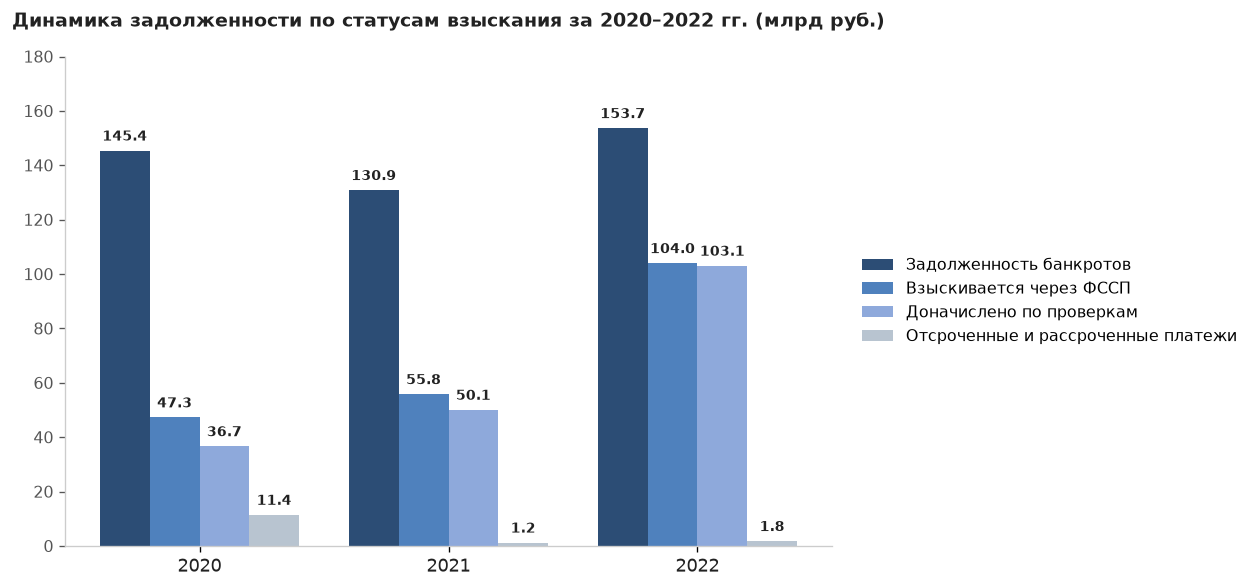

In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.join("data_processed", "fns_debt_rf_2020_2022.csv"))
df["Код_строки"] = df["Код_строки"].astype(str).str.strip()
df["Млрд_руб"] = df["Всего_тыс_руб"] / 1_000_000

codes = ("2205", "2070", "1040", "2391")
sub = df[df["Код_строки"].isin(codes)].pivot(index="Год", columns="Код_строки", values="Млрд_руб")

years = sub.index.astype(str)
x = range(len(years))
width = 0.20

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, ax = plt.subplots(figsize=(10.5, 5), dpi=120)

# Строго зафиксированные цвета проекта
b1 = ax.bar([i - 1.5 * width for i in x], sub.get("2205"), width, label="Задолженность банкротов", color="#2C4D75")
b2 = ax.bar([i - 0.5 * width for i in x], sub.get("2070"), width, label="Взыскивается через ФССП", color="#4F81BD")
b3 = ax.bar([i + 0.5 * width for i in x], sub.get("1040"), width, label="Доначислено по проверкам", color="#8EA9DB")
b4 = ax.bar([i + 1.5 * width for i in x], sub.get("2391"), width, label="Отсроченные и рассроченные платежи", color="#B8C4D0")

for bars in (b1, b2, b3, b4):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}",
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#222222")

ax.set_title("Динамика задолженности по статусам взыскания за 2020–2022 гг. (млрд руб.)", fontsize=11.5, fontweight="bold", pad=18, color="#222222")
ax.set_xticks(list(x))
ax.set_xticklabels(years, fontsize=11, color="#222222")
ax.set_ylim(0, 180)

ax.tick_params(axis="y", labelsize=9.5, colors="#555555")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9.5)

plt.tight_layout()
plt.show()


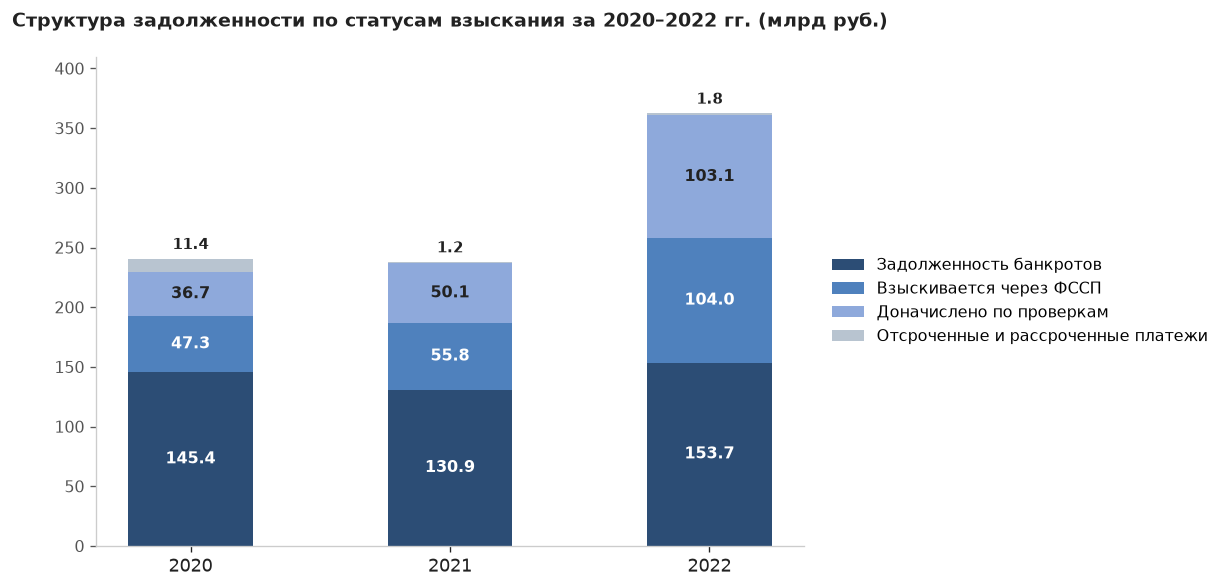

In [6]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.join("data_processed", "fns_debt_rf_2020_2022.csv"))
df["Код_строки"] = df["Код_строки"].astype(str).str.strip()
df["Млрд_руб"] = df["Всего_тыс_руб"] / 1_000_000

codes = ("2205", "2070", "1040", "2391")
sub = df[df["Код_строки"].isin(codes)].pivot(index="Год", columns="Код_строки", values="Млрд_руб").sort_index()

years = sub.index.astype(str)
s1 = sub.get("2205")
s2 = sub.get("2070")
s3 = sub.get("1040")
s4 = sub.get("2391")

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, ax = plt.subplots(figsize=(10, 5), dpi=120)

width = 0.48
ax.bar(years, s1, width, label="Задолженность банкротов", color="#2C4D75")
ax.bar(years, s2, width, bottom=s1, label="Взыскивается через ФССП", color="#4F81BD")
ax.bar(years, s3, width, bottom=s1 + s2, label="Доначислено по проверкам", color="#8EA9DB")
ax.bar(years, s4, width, bottom=s1 + s2 + s3, label="Отсроченные и рассроченные платежи", color="#B8C4D0")

for i in range(len(years)):
    v1 = s1.iloc[i]
    v2 = s2.iloc[i]
    v3 = s3.iloc[i]
    v4 = s4.iloc[i]
    total_top = v1 + v2 + v3 + v4

    ax.text(i, v1 / 2, f"{v1:.1f}", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    ax.text(i, v1 + v2 / 2, f"{v2:.1f}", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    ax.text(i, v1 + v2 + v3 / 2, f"{v3:.1f}", ha="center", va="center", color="#222222", fontweight="bold", fontsize=9.5)
    ax.text(i, total_top + 5, f"{v4:.1f}", ha="center", va="bottom", color="#222222", fontweight="bold", fontsize=9)

ax.set_title("Структура задолженности по статусам взыскания за 2020–2022 гг. (млрд руб.)", fontsize=11.5, fontweight="bold", pad=18, color="#222222")
ax.set_ylim(0, 410)

ax.tick_params(axis="x", labelsize=11, colors="#222222")
ax.tick_params(axis="y", labelsize=9.5, colors="#555555")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9.5)

plt.tight_layout()
plt.show()


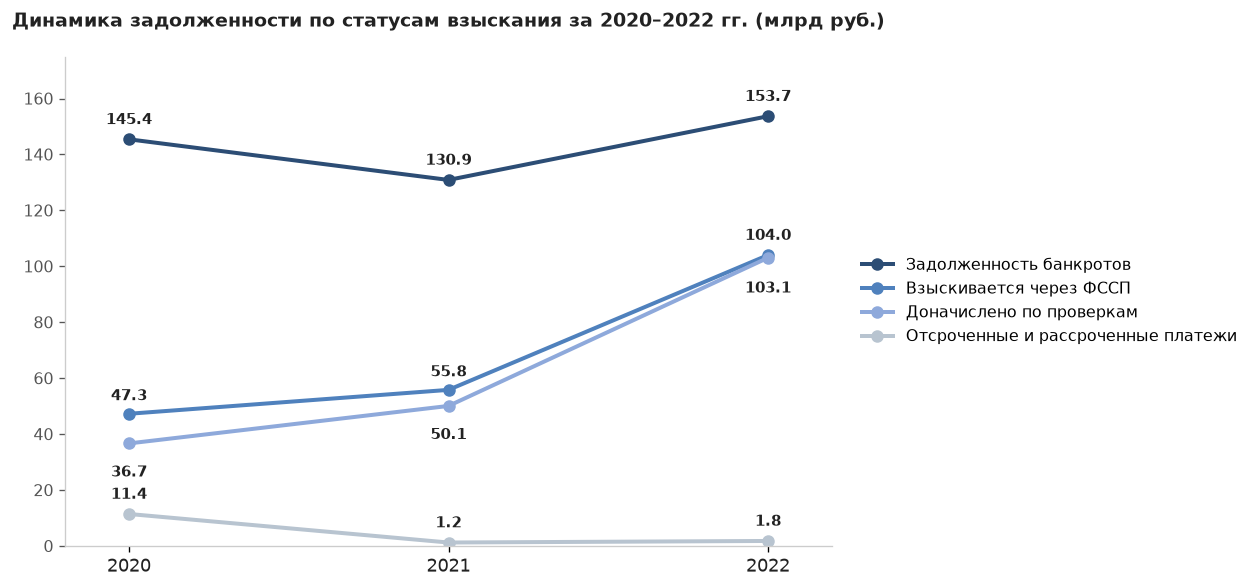

In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.join("data_processed", "fns_debt_rf_2020_2022.csv"))
df["Код_строки"] = df["Код_строки"].astype(str).str.strip()
df["Млрд_руб"] = df["Всего_тыс_руб"] / 1_000_000

codes = ("2205", "2070", "1040", "2391")
sub = df[df["Код_строки"].isin(codes)].pivot(index="Год", columns="Код_строки", values="Млрд_руб").sort_index()

years = sub.index.astype(str)
x = list(range(len(years)))

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, ax = plt.subplots(figsize=(10.5, 5), dpi=120)

series_cfg = (
    ("2205", "Задолженность банкротов", "#2C4D75", 7),
    ("2070", "Взыскивается через ФССП", "#4F81BD", 6),
    ("1040", "Доначислено по проверкам", "#8EA9DB", -13),
    ("2391", "Отсроченные и рассроченные платежи", "#B8C4D0", 7),
)

for code, label, color, y_offset in series_cfg:
    vals = sub.get(code).tolist()
    ax.plot(x, vals, marker="o", markersize=6.5, linewidth=2.4, color=color, label=label)
    for i, val in enumerate(vals):
        # В 2022 году две линии почти сходятся (104.0 и 103.1), поэтому разводим подписи вверх и вниз
        offset = y_offset
        if code == "2070" and i == 2:
            offset = 7
        elif code == "1040" and i == 2:
            offset = -14
        ax.annotate(f"{val:.1f}",
                    xy=(x[i], val),
                    xytext=(0, offset), textcoords="offset points",
                    ha="center", va="bottom" if offset > 0 else "top",
                    fontsize=9, fontweight="bold", color="#222222")

ax.set_title("Динамика задолженности по статусам взыскания за 2020–2022 гг. (млрд руб.)", fontsize=11.5, fontweight="bold", pad=18, color="#222222")
ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=11, color="#222222")
ax.set_xlim(-0.2, 2.2)
ax.set_ylim(0, 175)

ax.tick_params(axis="y", labelsize=9.5, colors="#555555")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9.5)

plt.tight_layout()
plt.show()


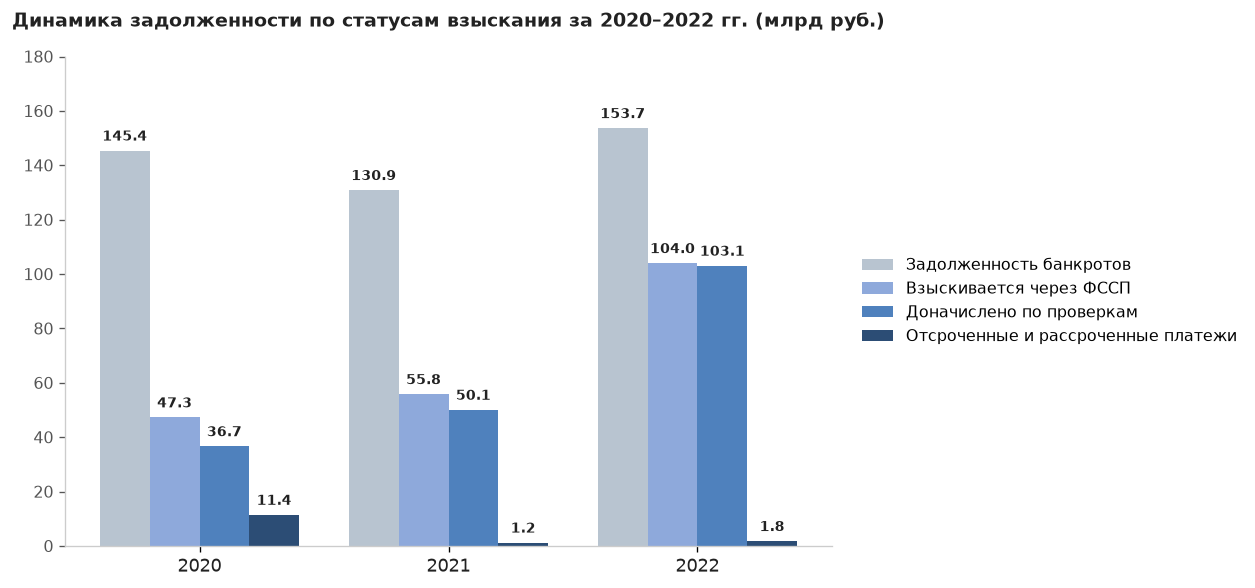

In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.join("data_processed", "fns_debt_rf_2020_2022.csv"))
df["Код_строки"] = df["Код_строки"].astype(str).str.strip()
df["Млрд_руб"] = df["Всего_тыс_руб"] / 1_000_000

codes = ("2205", "2070", "1040", "2391")
sub = df[df["Код_строки"].isin(codes)].pivot(index="Год", columns="Код_строки", values="Млрд_руб").sort_index()

years = sub.index.astype(str)
x = range(len(years))
width = 0.20

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, ax = plt.subplots(figsize=(10.5, 5), dpi=120)

# Инверсия зафиксированной палитры: от светлого для высоких столбцов к самому темному для низких
b1 = ax.bar([i - 1.5 * width for i in x], sub.get("2205"), width, label="Задолженность банкротов", color="#B8C4D0")
b2 = ax.bar([i - 0.5 * width for i in x], sub.get("2070"), width, label="Взыскивается через ФССП", color="#8EA9DB")
b3 = ax.bar([i + 0.5 * width for i in x], sub.get("1040"), width, label="Доначислено по проверкам", color="#4F81BD")
b4 = ax.bar([i + 1.5 * width for i in x], sub.get("2391"), width, label="Отсроченные и рассроченные платежи", color="#2C4D75")

for bars in (b1, b2, b3, b4):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}",
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#222222")

ax.set_title("Динамика задолженности по статусам взыскания за 2020–2022 гг. (млрд руб.)", fontsize=11.5, fontweight="bold", pad=18, color="#222222")
ax.set_xticks(list(x))
ax.set_xticklabels(years, fontsize=11, color="#222222")
ax.set_ylim(0, 180)

ax.tick_params(axis="y", labelsize=9.5, colors="#555555")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9.5)

plt.tight_layout()
plt.show()
